The idea for this project comes from [this GIS portfolio project guide](https://learn-gis-chi.vercel.app/projects/transit-desert/)

# Preparation

## Base map

Used OSM base map and municipal boundary from [GeoBoundaries](https://www.geoboundaries.org/index.html#getdata) to get a clipped map of Cape Town (exported an image of the OSM base map and clipped it using the municipal boundary as a mask layer).

## Loading spatial data

Loaded all the geospatial data (also clipped to municipal boundaries) - suburb boundaries, myciti stops, golden arrow stops, train stations, and taxi routes.

Loaded the survey data. 

## Reprojection

All the spatial data is in WGS84 (EPSG:4326) CRS. We're going to want to work with distances, so we want them in a projected CRS with meters as units of distance. Everything is reprojected to Hartebeesthoek94 Lo19 E-N (ESRI:102562). 

## Notes

"Walking distance" is often considered to be about 0.25 miles, which is about 400 meters. So we'll use 0.5 km as "walking distance" for this project.

# Transit supply computation

## 1) Walking distance buffer

Applied a 500 meter buffer to all transit stops (set to dissolve the resulting areas) to get the walking distance zone for each transit system. 

For taxis, the entire route is a stop, so i got a buffer around the lines of the taxi routes. For busses and trains, it was a buffer around the points representing the stops.

**Limitations (overestimation of access):**

- As mentioned in the data collection stage, the Golden Arrow bus stops are not all stops, so there will be some areas that appear to be within walking distance of a Golden Arrow bus stop but are not.

- At certain points, for all kinds of stops, the buffer will cross a highway or other large road without safe crossing. In these cases there will be areas that appear to be within walking distance of a stop but should not be considered so because the route to the stop is unsafe. For example: 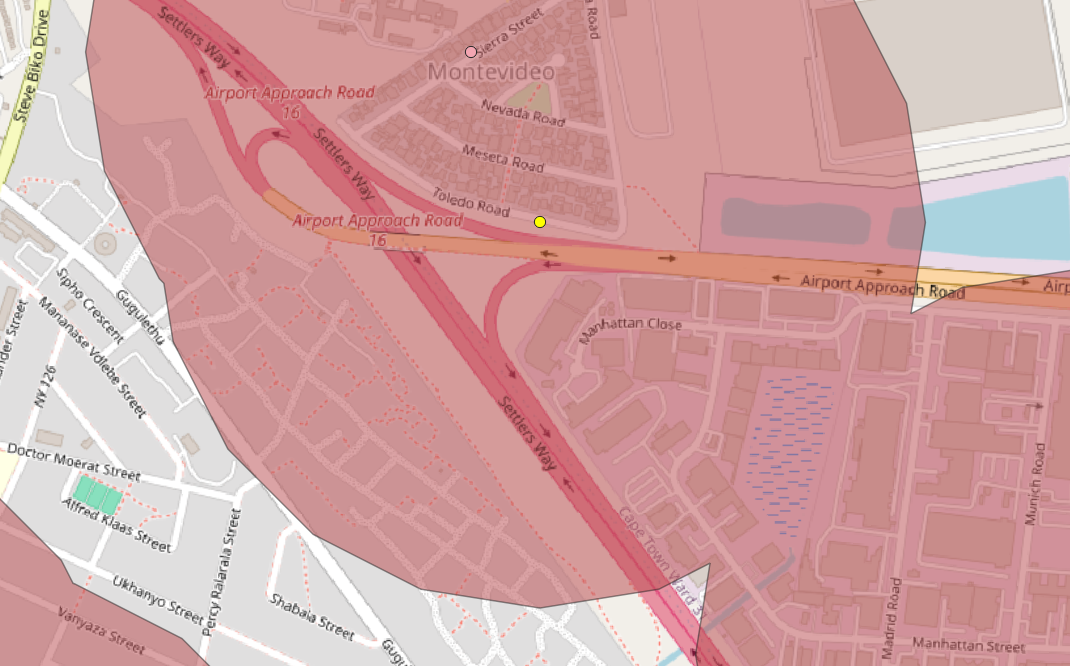

## 2) Spatial join

### i
For each transit system:
* Use Vector Analysis - Overlap Analysis to find the percentage cover by which the walking distance area overlaps the suburbs (saving as temporary layer only)
* Create a join on the suburbs layer to join the overlap layer percentage field

### ii
I also wanted to get the percentage covered by all trains and buses, and the percentage covered by any public transit. So i merged all bus and train walking distance areas to a temporary layer, dissolved the polygons, ran an overlap analysis, and added that as a join on suburbs. Then did the same with all transport walking distance layers.

### iii
Finally i exported the suburbs layer with all joined fields to have it persist in a file. "Coverage" fields (named in format like `myciti_bus_coverage_pc`) represent the percentage of the suburb within 500 meters of a bus stop/ train station/ taxi route/ etc.



# Transit need computation

## 1) Defining need

Continuing to follow the [project guide](https://learn-gis-chi.vercel.app/projects/transit-desert), we'll define transit need of an area as a weighted sum of the percentage of the population in that area that:
* lives below the poverty line
* has no private vehicle
* is elderly
* under 18

The sum we'll use is $$ \text{transit need} = 0.4 (\text{poverty}) + 0.4 (\text{no vehicle}) + 0.1 (\text{elderly}) + 0.1 (\text{under 18}) $$


## 2) Processing the survey data

### Transit need parameters from survey data fields

**Below poverty line:** There is a field giving household income (`hhincome`). It is not specified what period the income is given over, but based on the values, monthly income makes most sense. The [official poverty line](https://www.statssa.gov.za/publications/P03101/P031012024.pdf) in South Africa in 2024 was between R1109 (lower bound poverty line) and R1603 (upper bound poverty line) per individual per month. We can only estimate individual income from the survey - we can get the number of adults in the household and divide household income by household adults. We'll then calculate the percentage of households below the poverty line (could also calculate the number of individuals below the poverty line based on that estimation, but we'll stick with households). The income is given in ranges, and also includes values "Don't know" and "No income" - we'll use the median value of the range and ignore "Don't know".

**No private vehicle:** The survey has a boolean field indicating whether the household has a car (`hhasset_vehicle`). It would be useful to know how many vehicles there are per household compared to the number of potential drivers, but we can get the percentage of households with a vehicle.

**Under 18:** The survey data has number of people in each household surveyed (`hhsize`) and number of children in each household (`hhchildren`). To get an indication of the percentage of the population in the area that is under 18, we will use `hhsize` to get the total population size of each area and `hhchildren` to get the population size that is under 18.

**Elderly:** There is no field giving number of elderly people or pensioners in a household, but there is a boolean field for whether the household gets any pension income (`income_pension`). To get some metric that indicates share of elderly people in the population of an area, we can use the percentage of households where one or more people receive pension.


### Transforming survey data

In [1]:
import pandas as pd
import numpy as np
import statistics

In [2]:
df_survey = pd.read_csv(
    "../data/2024_Household_Survey_-4393438653176099798.csv",
    usecols=["suburb", "hhsize", "hhchildren", "hhasset_vehicle", "income_pension", "hhincome"]
)

First we'll get the values we need for each row.

| field | type |
|-------|-------|
| is_below_poverty_line | bool (as 0, 1) |
| not_has_private_vehicle | bool (as 0, 1) |
| num_people | int |
| num_children | int |
| has_pensioner | bool (as 0, 1) |


**Number of adults in the household (needed for other calulations)**

In [3]:
df_survey["hhadults"] = df_survey["hhsize"] - df_survey["hhchildren"]

In [4]:
# sanity check
any(df_survey["hhadults"] == 0)

False

**Household income**

In [5]:
print([value for value in df_survey["hhincome"].unique()])

["Don't know", ' R3 201 - R6 400', ' R12 801 - R25 600', ' R1 601 - R3 200', ' R801 - R1 600', ' R6 401 - R12 800 ', ' R1 - R400', ' R401 - R800', ' R25 601 - R51 200', ' R51 201 - R102 400', ' R102 401 - R204 800', 'No income', ' R204 801 or more', '1', '0']


In [6]:
df_survey.loc[(df_survey["hhincome"] == "1") | (df_survey["hhincome"] == "0")]

,suburb,hhsize,hhchildren,hhasset_vehicle,income_pension,hhincome,hhadults
1229,Maitland Garden Village/Ndabeni,2,0,No,Yes,1,2
1634,Scottsdene,6,4,No,Yes,0,2
3281,Philadelphia,4,2,No,Yes,1,2
4108,Belhar,4,2,Yes,No,0,2
5750,Claremont/Kenilworth,1,0,Yes,No,0,1
6992,Melkbosstrand,4,2,Yes,No,0,2
7826,Crossroads/New Crossroads/Nyanga,2,1,No,Yes,0,1


In [7]:
mapping = {
    "No income": 0,
    " R1 - R400": (1 + 400) / 2,
    " R401 - R800": ( 401 + 800 ) / 2,
    " R801 - R1 600": ( 801 + 1600 ) / 2,
    " R1 601 - R3 200": ( 1601 + 3200 ) / 2,
    " R3 201 - R6 400": ( 3201 + 6400 ) / 2,
    " R6 401 - R12 800 ": ( 6401 + 12800 ) / 2,
    " R12 801 - R25 600": ( 12801 + 25600 ) / 2,
    " R25 601 - R51 200": ( 25601 + 51200 ) / 2,
    " R51 201 - R102 400": ( 51201 + 102400 ) / 2,
    " R102 401 - R204 800": ( 102401 + 204800 ) / 2,
    " R204 801 or more": 204801, # this can stay as the low value because it will be above the poverty line even with hhsize of 100
    "Don't know": np.nan,
    "1": np.nan,
    "0": np.nan,
}

df_survey["hhincome_num"] = df_survey["hhincome"].map(mapping)

**Below poverty line**

In [8]:
def determine_poverty_status(row):
    if pd.isna(row["hhincome_num"]):
        return np.nan
    elif ( row["hhincome_num"] / row["hhadults"] ) <= 1109:
        return 1
    else:
        return 0

df_survey["is_below_poverty_line"] = df_survey.apply(determine_poverty_status, axis=1)

**Private vehicles**

In [9]:
print([value for value in df_survey["hhasset_vehicle"].unique()]) # check for odd values

['No', 'Yes']


In [10]:
df_survey["not_has_private_vehicle"] = df_survey["hhasset_vehicle"].map({"No": 1, "Yes": 0})

**Pensioners**

In [11]:
print([value for value in df_survey["income_pension"].unique()]) # check for odd values

['No', 'Yes', 'Refused to answer']


In [12]:
conditions = [
    df_survey["income_pension"] == "No",
    df_survey["income_pension"] == "Yes",
    df_survey["income_pension"] == "Refused to answer"
]
choices = [0, 1, np.nan]

df_survey["has_pensioner"] = np.select(conditions, choices, default=np.nan)

### Collecting by suburb

In [13]:
df_survey

,suburb,hhsize,hhchildren,hhasset_vehicle,income_pension,hhincome,hhadults,hhincome_num,is_below_poverty_line,not_has_private_vehicle,has_pensioner
0,Bo-Kaap,4,0,No,No,Don't know,4,NaN,NaN,1,0.0
1,Bo-Kaap,2,0,No,No,R3 201 - R6 400,2,4800.5,0.0,1,0.0
2,De Waterkant/Green Point/Sea Point,3,1,No,No,Don't know,2,NaN,NaN,1,0.0
3,Bothasig,2,0,Yes,No,R12 801 - R25 600,2,19200.5,0.0,0,0.0
4,Bothasig,3,1,Yes,No,Don't know,2,NaN,NaN,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
8313,Lakeside/Marina da Gama/Westlake,3,1,Yes,No,R25 601 - R51 200,2,38400.5,0.0,0,0.0
8314,Kommetjie/Scarborough,1,0,Yes,Yes,R204 801 or more,1,204801.0,0.0,0,1.0
8315,Somerset West,5,0,Yes,No,R6 401 - R12 800,5,9600.5,0.0,0,0.0
8316,Somerset West,2,0,Yes,Yes,R25 601 - R51 200,2,38400.5,0.0,0,1.0


In [14]:
# count number of rows in each suburb, skipping NaN in is_below_poverty_line:
df_survey["households_surveyed_on_poverty"] = df_survey.groupby("suburb")["is_below_poverty_line"].transform("count")
df_survey["households_surveyed_on_poverty"]

0       31.0
1       31.0
2       65.0
3       29.0
4       29.0
        ... 
8313    79.0
8314    49.0
8315    47.0
8316    47.0
8317    47.0
Name: households_surveyed_on_poverty, Length: 8318, dtype: float64

In [15]:
df_survey["households_surveyed_on_pensioners"] = df_survey.groupby("suburb")["has_pensioner"].transform("count")
df_survey["households_surveyed_on_vehicles"] = df_survey.groupby("suburb")["not_has_private_vehicle"].transform("count")

In [16]:
df_grouped = df_survey.groupby("suburb").agg(
    total_population=("hhsize", "sum"),
    children_population=("hhchildren", "sum"),
    adult_population=("hhadults", "sum"),
    households_below_poverty_line=("is_below_poverty_line", "sum"),
    households_without_private_vehicle=("not_has_private_vehicle", "sum"),
    households_with_pensioner=("has_pensioner", "sum"),
    households_surveyed_on_poverty=("households_surveyed_on_poverty", "mean"),
    households_surveyed_on_pensioners=("households_surveyed_on_pensioners", "mean"),
    households_surveyed_on_vehicles=("households_surveyed_on_vehicles", "mean")
)

In [17]:
df_grouped

,total_population,children_population,adult_population,households_below_poverty_line,households_without_private_vehicle,households_with_pensioner,households_surveyed_on_poverty,households_surveyed_on_pensioners,households_surveyed_on_vehicles
suburb,,,,,,,,,
Athlone,275,66,209,6.0,28,14.0,70.0,84.0,84.0
Atlantis,172,45,127,8.0,30,4.0,42.0,48.0,48.0
Beacon Valley,155,29,126,5.0,29,3.0,37.0,45.0,46.0
Belhar,247,63,184,15.0,38,5.0,71.0,72.0,72.0
Bellville,138,32,106,0.0,10,6.0,37.0,45.0,45.0
...,...,...,...,...,...,...,...,...,...
Witsand,152,46,106,10.0,40,2.0,45.0,48.0,48.0
Wolverivier,120,48,72,4.0,22,0.0,27.0,28.0,28.0
Woodlands,176,55,121,4.0,27,4.0,43.0,49.0,49.0


In [18]:
df_grouped["pct_households_below_poverty_line"] = 100 * df_grouped["households_below_poverty_line"] / df_grouped["households_surveyed_on_poverty"]
df_grouped["pct_households_without_private_vehicle"] = 100 * df_grouped["households_without_private_vehicle"] / df_grouped["households_surveyed_on_vehicles"]
df_grouped["pct_households_with_pensioners"] = 100 * df_grouped["households_with_pensioner"] / df_grouped["households_surveyed_on_pensioners"]
df_grouped["pct_population_children"] = 100 * df_grouped["children_population"] / df_grouped["total_population"]

In [19]:
df_final = df_grouped.drop(columns=[
    "total_population",
    "children_population",
    "adult_population",
    "households_below_poverty_line",
    "households_without_private_vehicle",
    "households_with_pensioner",
    "households_surveyed_on_poverty",
    "households_surveyed_on_pensioners",
    "households_surveyed_on_vehicles"
])

In [20]:
df_final

,pct_households_below_poverty_line,pct_households_without_private_vehicle,pct_households_with_pensioners,pct_population_children
suburb,,,,
Athlone,8.571429,33.333333,16.666667,24.000000
Atlantis,19.047619,62.500000,8.333333,26.162791
Beacon Valley,13.513514,63.043478,6.666667,18.709677
Belhar,21.126761,52.777778,6.944444,25.506073
Bellville,0.000000,22.222222,13.333333,23.188406
...,...,...,...,...
Witsand,22.222222,83.333333,4.166667,30.263158
Wolverivier,14.814815,78.571429,0.000000,40.000000
Woodlands,9.302326,55.102041,8.163265,31.250000


In [21]:
# df_final.to_csv("households_survey_data_2024_processed.csv")

## 3) Adding need field to suburbs in the project

1 - Created a layer with the suburb polygons and added joins to the survey data.

2 - Defined a function to calculate the transit need and made `transit_need_score` a calculated field in the layer.

Function:
```
@qgsfunction()
def transit_need_score(pct_in_poverty, pct_without_vehicle, pct_elderly, pct_children):
    return (
        (pct_in_poverty or 0) * 0.4 +
        (pct_without_vehicle or 0) * 0.4 +
        (pct_elderly or 0) * 0.1 +
        (pct_children or 0) * 0.1
    )
```

Expression:
```
transit_need_score(
pct_households_below_poverty_line,
pct_households_without_private_vehicle,
pct_households_with_pensioners,
pct_population_children
)
```

## 4) Classification

Initially created virtual layers for each of the different transit systems' coverages and for transit need, excluding rows where there was no survey data (needed to first create a join to transit_need_score on the coverage layer for this). Example query:
```
SELECT geometry, "name", "train_station_coverage_pc"
FROM "suburbs_with_public_transit_coverage"
WHERE "transit_need_score" IS NOT NULL
```

But realised fields can't be added to virtual layers, so created a layer for each public transit system containing only its coverage value. For each, created a join to transit need score so i could see which features did not have survey data (transit_need_score is NULL) and remove them. Also removed these features from the transit need layer.

I'm using these tutorials from [GeoAwesome](https://geoawesome.com/understanding-bivariate-maps-a-how-to-guide/) and [Joshua Stevens](https://www.joshuastevens.net/cartography/make-a-bivariate-choropleth-map/) to help learn how to create bivariate choropleth maps.

Used QGIS to calculate the breakpoints for categorizing the data into bins of equal counts, by using the symbology interface and classyfying with graduated symbology. Did this for each transit type.

```
Train
1: 0.000 - 1.915
2: 1.915 - 16.966
3: 16.966 - 86.720

GA Bus
1: 0.00 - 52.24
2: 52.24 - 86.15
3: 86.15 - 100.00

MyCiTi Bus
1: 0.000 - 0.03862
2: 0.03862 - 55.41888
3: 55.41888 - 100.00

Taxi
1: 0.000 - 86.7975
2: 86.7975 - 99.597
3: 99.597 - 100.00

Bus and Train
1: 0.00 - 64.61
2: 64.61 - 89.27
3: 89.27 - 100.00

All Public Transit
1: 11.329377192465 - 81.592488741802
2: 81.592488741802 - 98.334176942402
3: 98.334176942402 - 100.000
```

And for transit need score

```
Transit Need
1: 5.60 - 17.49
2: 17.49 - 36.26
3: 36.26 - 61.03
```

Then in each of these layers, created a class field. Exmaple of the expressions to calculate the class fields:
```
CASE
    WHEN "train_station_coverage_pc" <= 1.915 THEN 1
    WHEN "train_station_coverage_pc" > 1.915 AND "train_station_coverage_pc" <= 16.966 THEN 2
    ELSE 3
END
```

and

```
CASE
    WHEN "transit_need" <= 17.49 THEN 'A'
    WHEN "transit_need" > 17.49 AND "transit_need" <= 36.26 THEN 'B'
    ELSE 'C'
END
```

The classes for the public transit coverage are `[1, 2, 3]`, and the classes for transit need are `['A', 'B', 'C']`, which will be concatenated as suggested by the Joshua Stevens tutorial.

To create the bivariate classes, added a join on the transit coverage layers to the class of the transit need layer, and on each coverage layer added a `bivariate_class` field which is a concatenation of the univariates (expression in field calculator: `concat("transit_need_class", to_string("class"))`) 

## 5) Symbology

Selected this color pallette:
```
#64acbe  #627f8c  #574249
#b0d5df  #ad9ea5  #985356
#e8e8e8  #e4acac  #c85a5a
```

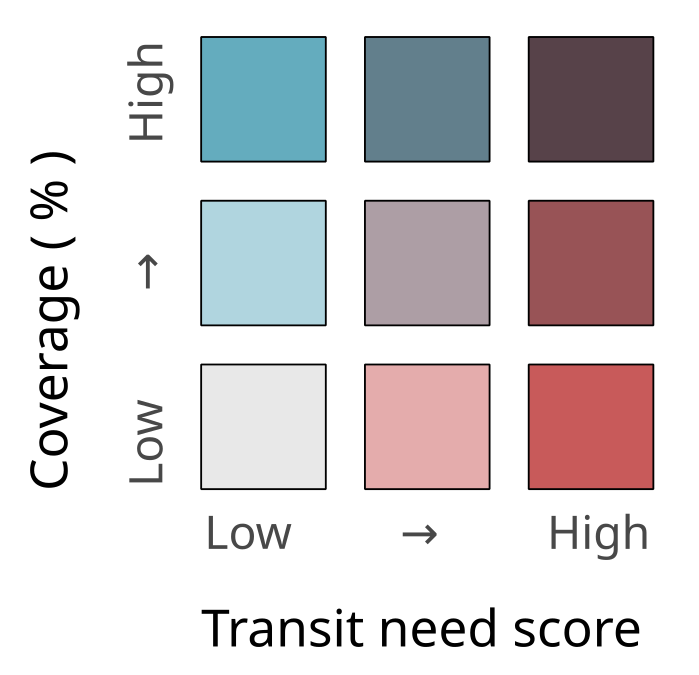

For each transit system, classified by the bivariate class and adjusted the color assignments to make most visual sense (e.g. high need, low cover is red, associated with a problem).

Saved the style as a QML file to easily load and apply for all transit system layers.

**It should be noted that colors can't be compared across transit systems, because classes are from division of the data into quantiles, not from absolute numbers. For example, in the map for trains, Endlovini and Enkanini are classified as high need and medium coverage, while in the map for all transit systems, Endlovini and Enkanini are classified as high need and high coverage. One may expect that since these areas have "medium coverage" by train stations, they would have at least medium coverage when considering all public transit. This is why it is important to make and take note of how the classification is done. This only affects coverage - need is constant across transit systems so will always have the same classification.**

## 6) Print layouts

Added a map theme for each layout i want (Transit need, Coverage against need - Train, Coverage against need - Taxi, ...)